# **Training, Calibration and Evaluation**

This notebook trains Logistic Regression and Random Forest on the three datasets, calibrates their predicted probabilities with Platt scaling and isotonic regression (implemented from scratch in `src/calibration.py`), evaluates them on the test set and generates the figures of the report. It uses the splits saved by [1_datasets.ipynb](1_datasets.ipynb).

### **Setup**

Imports the libraries and the project modules, sets the style and a single font size (`FONT_SIZE`) for all the figures, and creates the output folders: `results/` for the numerical results and `report/` for the figures. It also defines the two models with their hyperparameters (`MODELS`) and the color of each model and calibration method (`MODEL_COLORS`), used in all the figures.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from src.calibration import IsotonicCalibrator, PlattScaling
from src.data import DATASETS, RANDOM_STATE, load_splits
from src.metrics import evaluate
from src.plots import calibration_size_curve, prediction_histogram, reliability_axes, reliability_curve

sns.set_theme(style="whitegrid", context="paper")
FONT_SIZE = 10
plt.rcParams.update({"font.size": FONT_SIZE, "axes.titlesize": FONT_SIZE, "axes.labelsize": FONT_SIZE,
                     "xtick.labelsize": FONT_SIZE, "ytick.labelsize": FONT_SIZE, "legend.fontsize": FONT_SIZE,
                     "figure.titlesize": FONT_SIZE})
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR = ROOT / "report" 
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "LR": lambda: LogisticRegression(max_iter=500),
    "RF": lambda: RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, n_estimators=101),
}

MODEL_COLORS = {
    ("LR", "uncalibrated"): "#eb6834",
    ("LR", "platt"): "#56b4e9",
    ("LR", "isotonic"): "#1baf7a",
    ("RF", "uncalibrated"): "#d62728",
    ("RF", "platt"): "#003366",
    ("RF", "isotonic"): "#027E02",
}

### **Loading the Splits**

Loads the training, calibration and test sets of each dataset, saved by the first notebook.

In [2]:
data = {}
for name in DATASETS:
    X_train, X_cal, X_test, y_train, y_cal, y_test = load_splits(name)
    data[name] = {"train": (X_train, y_train), "cal": (X_cal, y_cal), "test": (X_test, y_test)}

### **Training**

Trains both models on the training set of each dataset.

In [3]:
models = {}
for name in DATASETS:
    X, y = data[name]["train"]
    for model_name, make in MODELS.items():
        model = make().fit(X, y)
        models[name, model_name] = model
        iterations = f"  ({model.n_iter_[0]} iterations)" if model_name == "LR" else ""
        print(f"{name:10s} {model_name}: {model}{iterations}")

higgs      LR: LogisticRegression(max_iter=500)  (17 iterations)
higgs      RF: RandomForestClassifier(n_estimators=101, n_jobs=-1, random_state=42)
covertype  LR: LogisticRegression(max_iter=500)  (93 iterations)
covertype  RF: RandomForestClassifier(n_estimators=101, n_jobs=-1, random_state=42)
adult      LR: LogisticRegression(max_iter=500)  (82 iterations)
adult      RF: RandomForestClassifier(n_estimators=101, n_jobs=-1, random_state=42)


### **Uncalibrated Predictions**

Computes, once for each model, the predicted probability of the positive class on the calibration and test sets. These uncalibrated predictions are the input of the calibrators, and are saved in `results/uncalibrated_outputs.npz`.

In [4]:
outputs = {}
for (name, model_name), model in models.items():
    for split in ("cal", "test"):
        outputs[name, model_name, split] = model.predict_proba(data[name][split][0])[:,1]

np.savez_compressed(RESULTS_DIR / "uncalibrated_outputs.npz", **{f"{n}_{m}_{s}": p for (n, m, s), p in outputs.items()})

### **Calibration**

Fits Platt scaling and isotonic regression on the uncalibrated predictions of the calibration set, and applies them to the predictions of the calibration and test sets. The probabilities of every dataset, model and method, including the uncalibrated ones, are stored in `probs`.

In [5]:
CALIBRATORS = {"platt": PlattScaling, "isotonic": IsotonicCalibrator}
METHODS = ["uncalibrated", *CALIBRATORS]

calibrators, probs = {}, {}
for name, model_name in models:
    y_cal = data[name]["cal"][1]
    p_cal, p_test = outputs[name, model_name, "cal"], outputs[name, model_name, "test"]
    probs[name, model_name, "uncalibrated"] = {"cal": p_cal, "test": p_test}
    for method, Calibrator in CALIBRATORS.items():
        calibrator = Calibrator().fit(p_cal, y_cal)
        calibrators[name, model_name, method] = calibrator
        probs[name, model_name, method] = {"cal": calibrator.predict_proba(p_cal), "test": calibrator.predict_proba(p_test)}

### **Metrics on the Calibration Set**

As a check of the fit, compares the log-loss and the Brier score on the calibration set itself before and after each calibrator.

In [6]:
rows = []
for name, model_name in models:
    y_cal = data[name]["cal"][1]
    for method in METHODS:
        rows.append({"dataset": name, "model": model_name, "method": method,
                     **evaluate(y_cal, probs[name, model_name, method]["cal"])})
cal_metrics = pd.DataFrame(rows).set_index(["dataset", "model", "method"])

iso = cal_metrics.xs("isotonic", level="method")[["log_loss", "brier"]]
uncal = cal_metrics.xs("uncalibrated", level="method")[["log_loss", "brier"]]
table = cal_metrics[["log_loss", "brier"]].unstack("method")
table.loc[list(DATASETS), [(m, meth) for m in ("log_loss", "brier") for meth in METHODS]].round(4)

log_loss                         brier                 
method          uncalibrated   platt isotonic uncalibrated   platt isotonic
dataset   model                                                            
higgs     LR          0.6389  0.6372   0.6340       0.2237  0.2233   0.2221
          RF          0.5639  0.5551   0.5520       0.1910  0.1879   0.1870
covertype LR          0.5106  0.5085   0.5016       0.1685  0.1677   0.1659
          RF          0.3216  0.2989   0.2910       0.0971  0.0922   0.0907
adult     LR          0.3198  0.3356   0.3150       0.1024  0.1050   0.1013
          RF          0.3804  0.3378   0.3236       0.1025  0.1043   0.1017

### **Metrics on the Test Set**

Computes accuracy, log-loss, Brier score and ECE on the test set for every dataset, model and method, together with those of the constant predictor equal to the rate of positives of the training set, used as a reference. The table is saved in `results/test_metrics.csv`.

In [7]:
rows = []
for name in DATASETS:
    y_train, y_test = data[name]["train"][1], data[name]["test"][1]
    rows.append({"dataset": name, "model": "constant", "method": "-",
                 **evaluate(y_test, np.full(len(y_test), y_train.mean()))})
    for model_name in MODELS:
        for method in METHODS:
            rows.append({"dataset": name, "model": model_name, "method": method,
                         **evaluate(y_test, probs[name, model_name, method]["test"])})

test_metrics = pd.DataFrame(rows)
test_metrics.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
test_metrics.set_index(["dataset", "model", "method"]).round(4)

accuracy  log_loss   brier     ece
dataset   model    method                                          
higgs     constant -               0.5285    0.6915  0.2492  0.0001
          LR       uncalibrated    0.6408    0.6372  0.2227  0.0277
                   platt           0.6420    0.6350  0.2222  0.0224
                   isotonic        0.6404    0.6462  0.2220  0.0162
          RF       uncalibrated    0.7055    0.5674  0.1928  0.0421
                   platt           0.7055    0.5614  0.1908  0.0168
                   isotonic        0.7048    0.5653  0.1910  0.0156
covertype constant -               0.5124    0.6928  0.2498  0.0000
          LR       uncalibrated    0.7580    0.5106  0.1687  0.0270
                   platt           0.7582    0.5090  0.1679  0.0117
                   isotonic        0.7588    0.5109  0.1677  0.0150
          RF       uncalibrated    0.8734    0.3259  0.0970  0.0694
                   platt           0.8726    0.2981  0.0915  0.0182
                   isotonic        0.8745    0.3138  0.0912  0.0096
adult     constant -               0.7521    0.5600  0.1864  0.0000
          LR       uncalibrated    0.8510    0.3190  0.1026  0.0084
                   platt           0.8514    0.3356  0.1053  0.0432
                   isotonic        0.8509    0.3186  0.1026  0.0056
          RF       uncalibrated    0.8515    0.3447  0.1041  0.0203
                   platt           0.8525    0.3413  0.1061  0.0350
                   isotonic        0.8534    0.3275  0.1039  0.0119

### **Reliability Diagrams**

For each dataset, draws the reliability diagrams of the test set before and after calibration, for Logistic Regression (left) and Random Forest (right), with the histograms of the predicted probabilities below them.

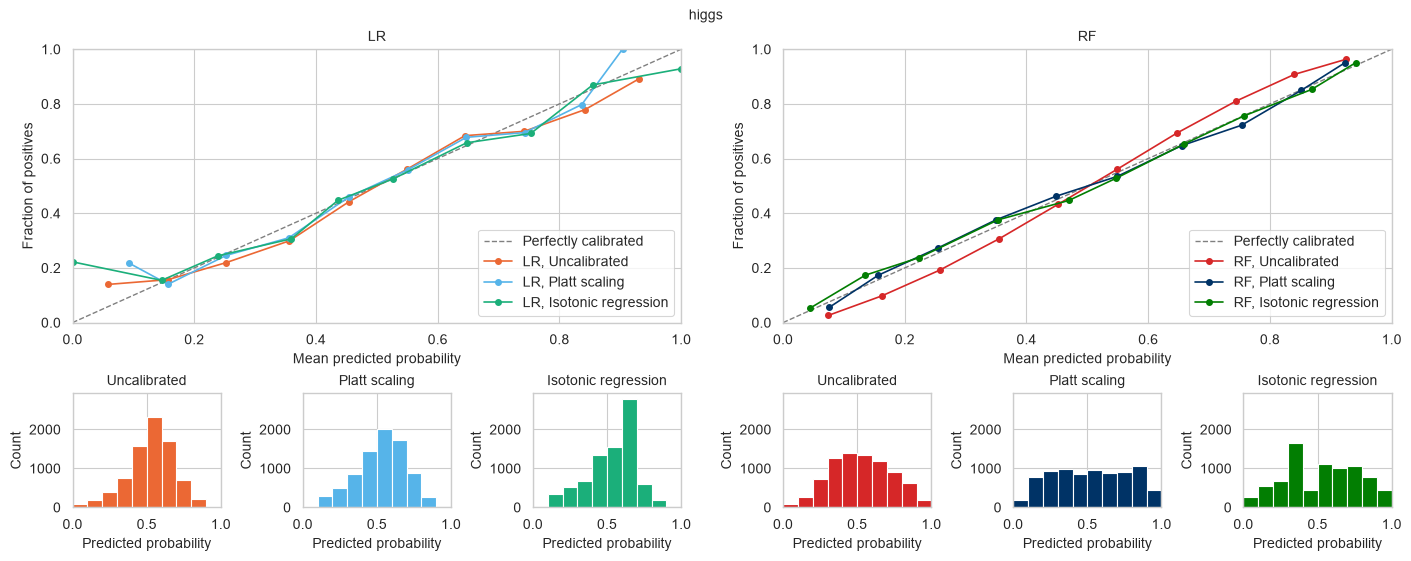

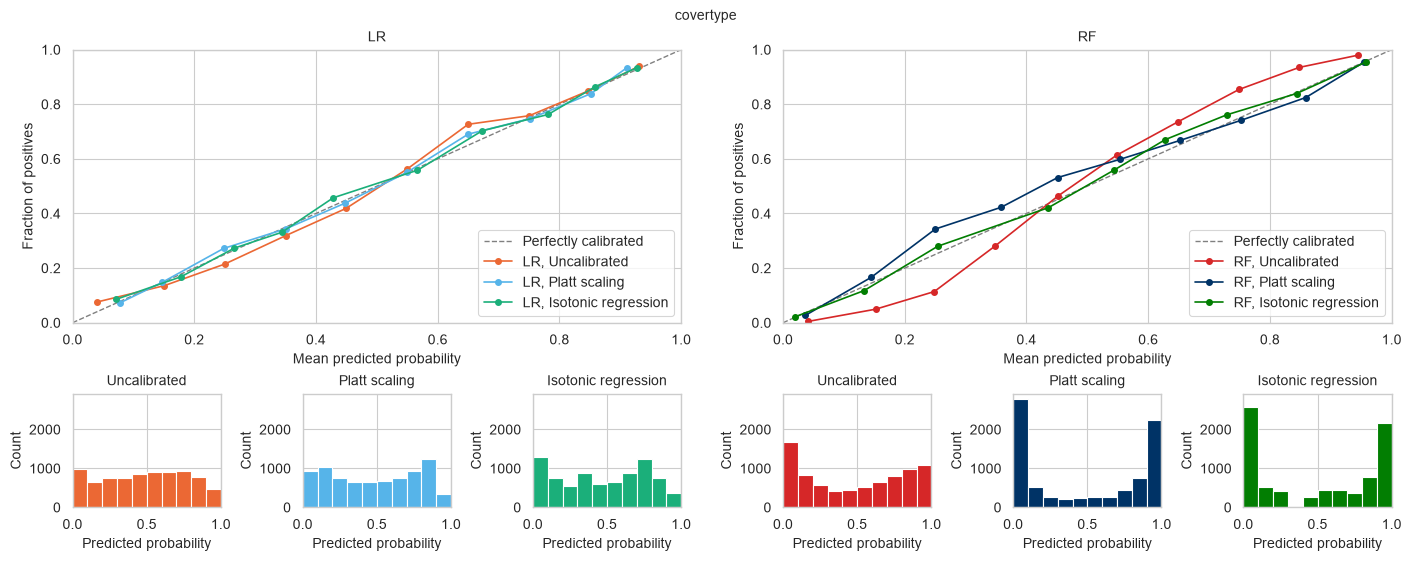

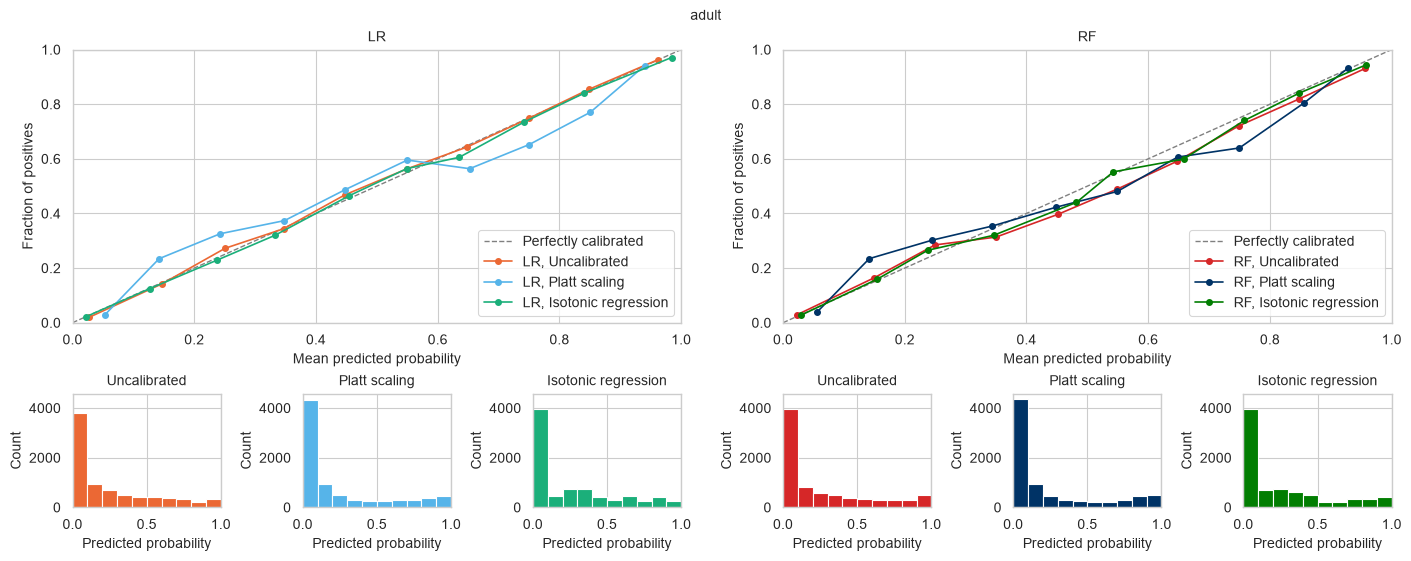

In [12]:
LABELS = {"uncalibrated": "Uncalibrated", "platt": "Platt scaling", "isotonic": "Isotonic regression"}
MODEL_STYLES = {
    "LR": {"marker": "o", "linestyle": "-"},
    "RF": {"marker": "o", "linestyle": "-"},
}

def reliability_figure_side_by_side(name):
    y_test = data[name]["test"][1]
    fig = plt.figure(figsize=(14, 5.5), layout="constrained")
    fig.suptitle(name)

    subfigs = fig.subfigures(1, len(MODELS), wspace=0.03)

    shared_hist = None
    for i, model_name in enumerate(MODELS):
        subfig = subfigs[i]
        gs = subfig.add_gridspec(2, len(METHODS), height_ratios=[2.4, 1])

        ax = subfig.add_subplot(gs[0, :])
        reliability_axes(ax, diagonal_label="Perfectly calibrated")
        ax.set_aspect("auto")
        ax.set_box_aspect(None)
        ax.set_title(model_name)
        

        for j, method in enumerate(METHODS):
            p = probs[name, model_name, method]["test"]
            label = f"{model_name}, {LABELS[method]}"
            color = MODEL_COLORS[model_name, method]

            reliability_curve(ax, y_test, p, color=color, markersize=4,
                              label=label, **MODEL_STYLES[model_name])

            ax_hist = subfig.add_subplot(gs[1, j], sharey=shared_hist)
            prediction_histogram(ax_hist, p, color)
            ax_hist.set_xticks([0, 0.5, 1])   
            ax_hist.set_title(LABELS[method])
            if shared_hist is None:
                shared_hist = ax_hist

        ax.legend(loc="lower right")

    return fig

for name in DATASETS:
    fig = reliability_figure_side_by_side(name)
    fig.savefig(FIG_DIR / f"reliability_{name}_side_by_side.pdf", bbox_inches="tight", dpi=1200)
    plt.show()

### **Calibration Maps**

For each model, draws the calibration maps fitted on the calibration set (the Platt sigmoid and the isotonic step function, evaluated on a fine grid of $[0, 1]$) next to the uncalibrated reliability points of the test set, which represent the ideal correction.

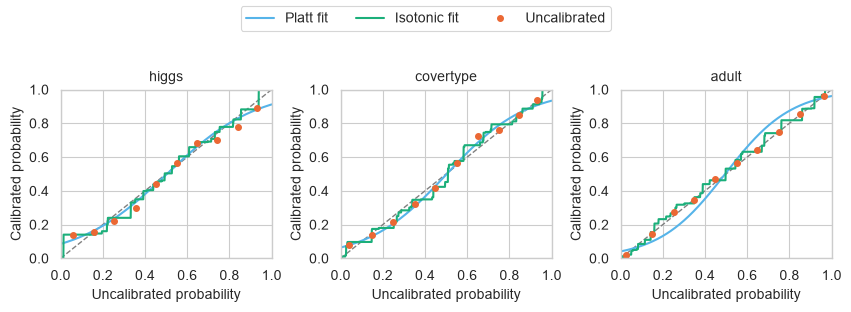

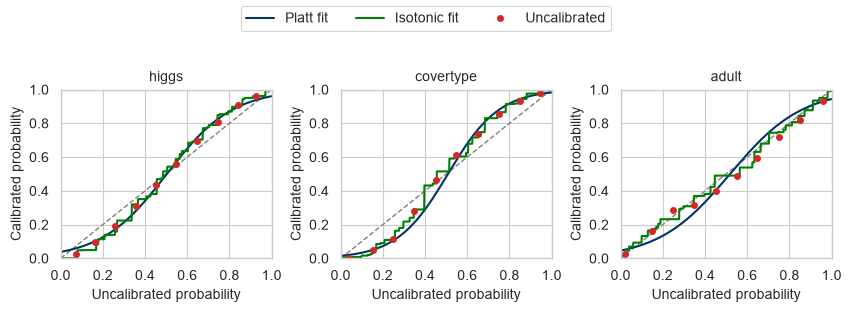

In [13]:
FIT_LABELS = {"platt": "Platt fit", "isotonic": "Isotonic fit"}

def calibration_maps_figure(model_name):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(8.4, 3.1), layout="constrained")
    grid = np.linspace(0, 1, 2001)      
    for ax, name in zip(axes, DATASETS):
        reliability_axes(ax, xlabel="Uncalibrated probability", ylabel="Calibrated probability")
        ax.set_box_aspect(0.8)   
        for method in CALIBRATORS:
            ax.plot(grid, calibrators[name, model_name, method].predict_proba(grid),
                    color=MODEL_COLORS[model_name, method], linewidth=1.5, label=FIT_LABELS[method])
        reliability_curve(ax, data[name]["test"][1], probs[name, model_name, "uncalibrated"]["test"],
                          color=MODEL_COLORS[model_name, "uncalibrated"], marker="o", linestyle="none", markersize=4,
                          label=LABELS["uncalibrated"])
        ax.set_title(name)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=3)   
    return fig


for model_name in MODELS:
    fig = calibration_maps_figure(model_name)
    fig.savefig(FIG_DIR / f"calibration_maps_{model_name}.pdf", bbox_inches="tight", dpi=1200)
    plt.show()

### **Test Metrics**

Draws the test metrics of each model and method as grouped bars, with the constant predictor in grey and the value of each bar above it.

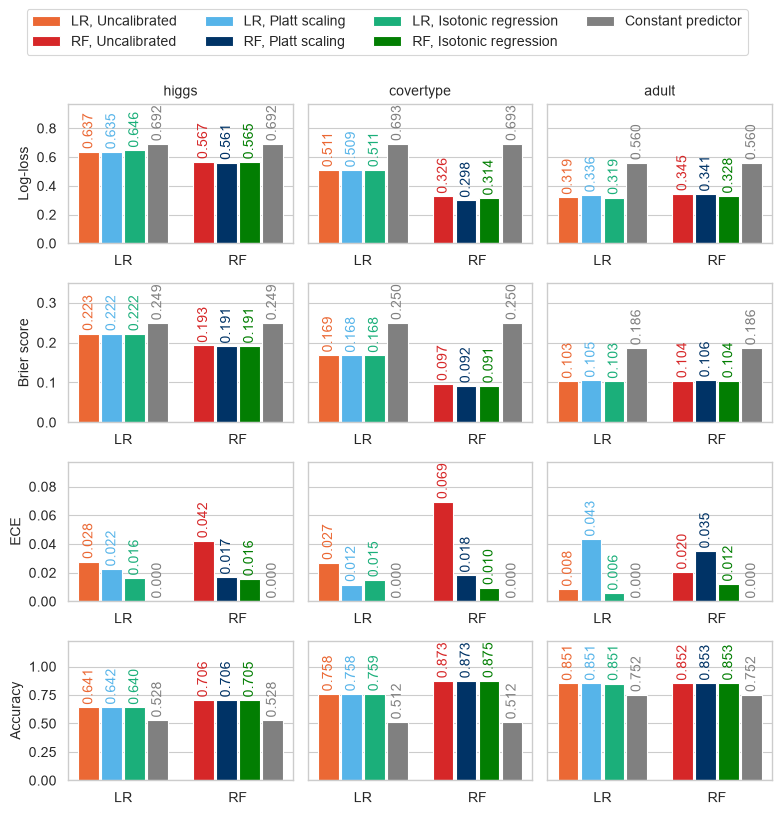

In [14]:
METRIC_LABELS = {"log_loss": "Log-loss", "brier": "Brier score", "ece": "ECE", "accuracy": "Accuracy"}
BARS = [*METHODS, "constant"]
WIDTH = 0.8 / len(BARS)

fig, axes = plt.subplots(len(METRIC_LABELS), len(DATASETS), figsize=(8, 7.5), sharey="row")
containers = []
for i, (metric, metric_label) in enumerate(METRIC_LABELS.items()):
    for j, name in enumerate(DATASETS):
        ax = axes[i, j]
        values = test_metrics[test_metrics["dataset"] == name].set_index(["model", "method"])[metric]
        for k, bar in enumerate(BARS):
            for m, model in enumerate(MODELS):
                if bar == "constant":
                    height, color, label = values["constant", "-"], "grey", "Constant predictor"
                else:
                    height, color, label = values[model, bar], MODEL_COLORS[model, bar], f"{model}, {LABELS[bar]}"
                x = m + (k - (len(BARS) - 1) / 2) * WIDTH
                bars = ax.bar(x, height, 0.9 * WIDTH, color=color, label=label)
                containers.append((ax, bars, color))
        ax.set(xticks=np.arange(len(MODELS)), xticklabels=list(MODELS), title=name if i == 0 else "",
               ylabel=metric_label if j == 0 else "")
        ax.grid(axis="x", visible=False)
    axes[i, 0].set_ylim(0, 1.4 * test_metrics[metric].max())  
handles, labels = axes[0, 0].get_legend_handles_labels()
legend = dict(zip(labels, handles))   
fig.legend(legend.values(), legend.keys(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.09))
fig.tight_layout()

for ax, bars, color in containers:
    ax.bar_label(bars, fmt="%.3f", color=color, rotation=90, padding=2, fontsize=FONT_SIZE)
fig.savefig(FIG_DIR / "test_metrics.pdf", bbox_inches="tight", dpi=1200)

### **Effect of the Calibration Set Size (Figure 6)**

Refits the calibrators on nested, stratified subsets of the calibration set, whose size doubles from 32 to 4,096 examples, and on the whole set, without retraining the models, and evaluates them on the test set. The results are saved in `results/calibration_size.csv`, and the figure shows the test Brier score against the size of the calibration set, with the uncalibrated model as a horizontal line.

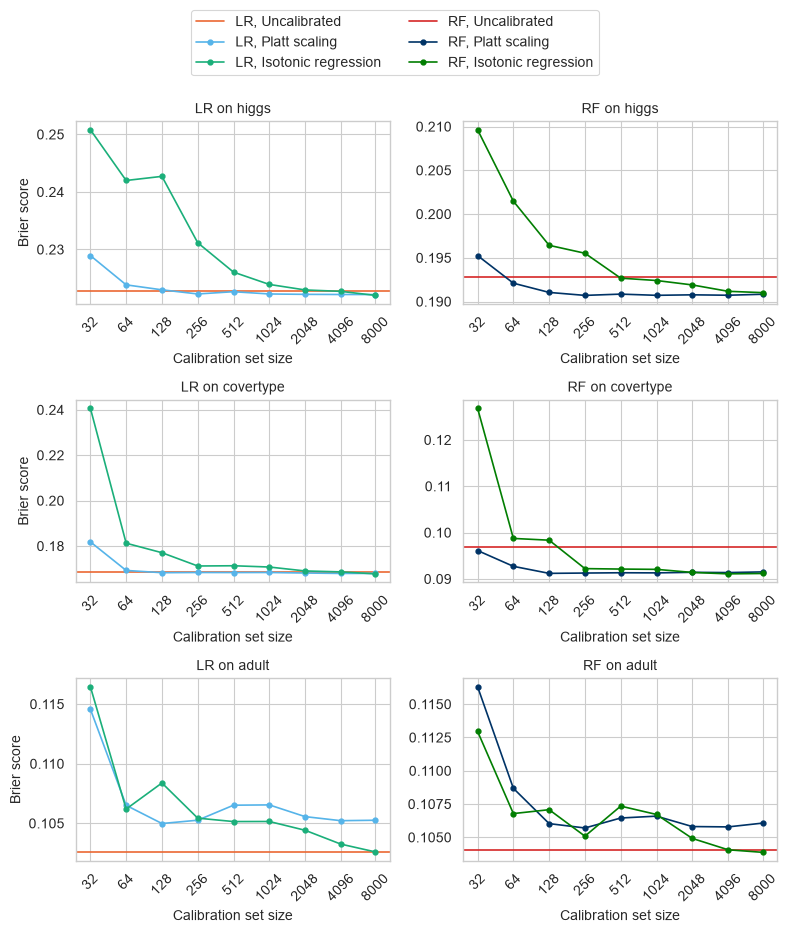

: 

In [ ]:
CAL_SIZES = [2 ** k for k in range(5, 13)]   


def stratified_order(y, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    rank = np.empty(len(y))
    for c in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == c))
        rank[idx] = (np.arange(len(idx)) + 0.5) / len(idx)
    return np.argsort(rank, kind="stable")


rows = []
for name, model_name in models:
    y_cal, y_test = data[name]["cal"][1], data[name]["test"][1]
    p_cal, p_test = outputs[name, model_name, "cal"], outputs[name, model_name, "test"]
    order = stratified_order(y_cal)
    for n in CAL_SIZES + [len(y_cal)]:
        idx = order[:n]
        info = {"dataset": name, "model": model_name, "size": n, "positives": int(y_cal[idx].sum())}
        rows.append({**info, "method": "uncalibrated", **evaluate(y_test, p_test)})
        for method, Calibrator in CALIBRATORS.items():
            p = Calibrator().fit(p_cal[idx], y_cal[idx]).predict_proba(p_test)
            rows.append({**info, "method": method, **evaluate(y_test, p)})

cal_size = pd.DataFrame(rows)
cal_size.to_csv(RESULTS_DIR / "calibration_size.csv", index=False)



fig, axes = plt.subplots(len(DATASETS), len(MODELS), figsize=(8, 8.5))
for i, name in enumerate(DATASETS):
    for j, model_name in enumerate(MODELS):
        g = cal_size[(cal_size["dataset"] == name) & (cal_size["model"] == model_name)]
        sizes = g.loc[g["method"] == "platt", "size"].to_numpy()
        series = [(g.loc[g["method"] == m, "brier"].to_numpy(), MODEL_COLORS[model_name, m],
                   f"{model_name}, {LABELS[m]}")
                  for m in CALIBRATORS]
        uncal = g.loc[g["method"] == "uncalibrated", "brier"].iloc[0]
        calibration_size_curve(axes[i, j], sizes, series, uncal, MODEL_COLORS[model_name, "uncalibrated"],
                               f"{model_name}, {LABELS['uncalibrated']}")
        axes[i, j].set(title=f"{model_name} on {name}", xlabel="Calibration set size",
                       ylabel="Brier score" if j == 0 else "")
handles_lr, labels_lr = axes[0, 0].get_legend_handles_labels()
handles_rf, labels_rf = axes[0, 1].get_legend_handles_labels()
fig.legend(handles_lr + handles_rf, labels_lr + labels_rf, loc="upper center", ncol=2,
           bbox_to_anchor=(0.5, 1.1))  
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration_size.pdf", bbox_inches="tight", dpi=1200)